<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A perfect round trip can preserve the wrong amount

**Does recreating every input byte prove that a fixed-width record was interpreted correctly?**
We will decode a small ledger, inspect its field boundaries, re-encode every record,
and reconcile the decoded amounts against separately supplied control totals.
Then we will change only the decimal scale while keeping the physical record layout fixed.

The six records and control totals are **synthetic teaching inputs**, denominated in
illustrative USD. `D` adds to the account total and `C` subtracts under this fixture's
stated convention. They are not banking records or a general debit/credit accounting rule.
The worker performs the parsing and formatting; SQL retains exact DECIMAL values.

## Choose the decimal interpretation

`AMOUNT_SCALE=2` is the fixture's documented layout: the final nine display digits
have two implied decimal places. The experiment permits `3`, which keeps nine bytes
but interprets three decimal places. There is no decimal-point byte in the record.
Restart and run all after changing this integer. [Setup and execution](README.md).

The control totals always retain the fixture's documented meaning. Changing this
parameter does not rewrite the records or redefine those controls.

In [1]:
AMOUNT_SCALE = 2

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
from pathlib import Path
from tempfile import TemporaryDirectory
from notebook_support import finish, prose, theme

if type(AMOUNT_SCALE) is not int or AMOUNT_SCALE not in {2, 3}:
    raise ValueError("AMOUNT_SCALE must be the integer 2 or 3.")
layout_fields = decoded_rows = reconciliation = checks = pd.DataFrame()
theme()
con = haybarn.connect()
fixture_directory = TemporaryDirectory(prefix="vgi-fixedformat-notebook-")
ledger_path = Path(fixture_directory.name) / "ledger.dat"
ledger_path_sql = str(ledger_path).replace("'", "''")
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-fixedformat/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-fixedformat/notebooks/pyproject.toml.

## Connect to the native release

`github-auto` retrieves the pinned platform release. The notebook needs no Rust
compiler or local worker build. The `fixed.main` catalog provides scalar unpack/pack,
layout inspection and file readers. We keep the default SQL catalog for our local tables.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fixed' (TYPE vgi,
 LOCATION 'github-auto://Query-farm/vgi-fixedformat@v0.12.0');

,Success


## Treat the layout as part of the data contract

The spec is a bind-time constant because it determines the returned STRUCT type.
A SQL macro makes that same literal spec available to unpack, pack and file-read calls.
The parameter appears explicitly in its `scale` field. `describe_fixed` supplies the
byte offsets and SQL types instead of relying on hand-counted boundaries.

In [4]:
%%sql
CREATE MACRO ledger_layout() AS '[
 {"name":"account", "type":"str", "width":6},
 {"name":"direction", "type":"str", "width":1},
 {"name":"reference", "type":"str", "width":8},
 {"name":"amount", "type":"decimal", "digits":9, "scale":{{ AMOUNT_SCALE }}}
]';
CREATE TABLE layout_description AS
 SELECT * FROM fixed.main.describe_fixed(ledger_layout());
SELECT path, kind, sql_type, byte_offset, width FROM layout_description ORDER BY byte_offset;

,path,kind,sql_type,byte_offset,width
0,account,text,VARCHAR,0,6
1,direction,text,VARCHAR,6,1
2,reference,text,VARCHAR,7,8
3,amount,decimal (display),"DECIMAL(9,2)",15,9


## Preserve raw bytes beside decoded fields

Each ASCII record is 24 bytes: account, direction, reference and the nine-digit amount.
The expected account totals below are a separate synthetic control manifest, entered
as decimal literals. We do not derive the expected totals by re-parsing the same bytes.
The raw strings have no delimiters; the spaces in a normal report would be presentation.

In [5]:
%%sql
CREATE TABLE raw_records(record_id INTEGER, raw_record VARCHAR);
INSERT INTO raw_records VALUES
 (1, 'A10001DREF00001000013425'),
 (2, 'A10001DREF00002000005000'),
 (3, 'A10001CREF00003000003000'),
 (4, 'A20002CREF00004000001240'),
 (5, 'A20002DREF00005000000000'),
 (6, 'A20002DREF00006000009999');
CREATE TABLE control_totals(account VARCHAR, expected_usd DECIMAL(12,2));
INSERT INTO control_totals VALUES ('A10001', 154.25), ('A20002', 87.59);
CREATE TABLE parsed_structs AS
 SELECT *, fixed.main.unpack_fixed(raw_record, ledger_layout()) AS fields FROM raw_records;
CREATE TABLE decoded AS
 SELECT record_id, raw_record, fields.account AS account, fields.direction AS direction,
        fields.reference AS reference, fields.amount AS amount
 FROM parsed_structs;
SELECT record_id, raw_record, account, direction, reference, amount,
       typeof(amount) AS amount_type FROM decoded ORDER BY record_id;

,record_id,raw_record,account,direction,reference,amount,amount_type
0,1,A10001DREF00001000013425,A10001,D,REF00001,134.25,"DECIMAL(9,2)"
1,2,A10001DREF00002000005000,A10001,D,REF00002,50.00,"DECIMAL(9,2)"
2,3,A10001CREF00003000003000,A10001,C,REF00003,30.00,"DECIMAL(9,2)"
3,4,A20002CREF00004000001240,A20002,C,REF00004,12.40,"DECIMAL(9,2)"
4,5,A20002DREF00005000000000,A20002,D,REF00005,0.00,"DECIMAL(9,2)"
5,6,A20002DREF00006000009999,A20002,D,REF00006,99.99,"DECIMAL(9,2)"


In [6]:
%%sql decoded_rows <<
SELECT * FROM decoded ORDER BY record_id;

In [7]:
%%sql layout_fields <<
SELECT path, byte_offset, width FROM layout_description ORDER BY byte_offset;

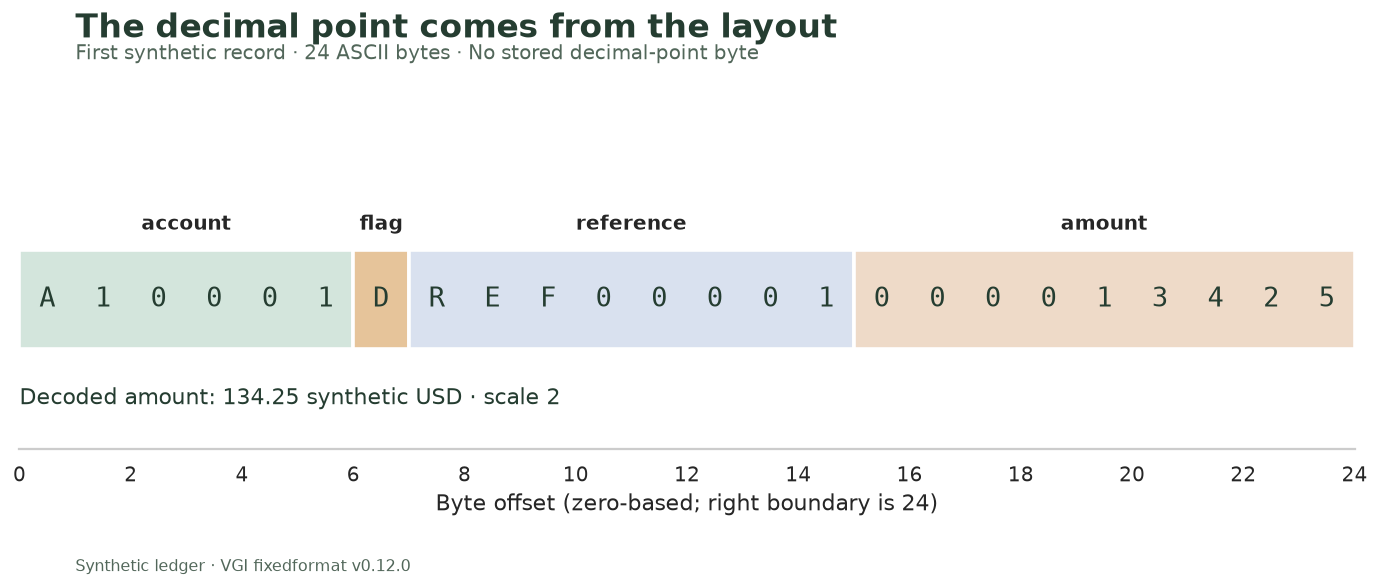

The amount field occupies **9 bytes**, starting at offset **15**. Under scale **2**, its first value is **134.25 synthetic USD**. Changing the scale changes the value without moving any field boundary.

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["#d3e5dc", "#e6c49a", "#d9e1ef", "#eedac8"]
record = decoded_rows.iloc[0]
for field, color in zip(layout_fields.itertuples(), colors):
    left, width = int(field.byte_offset), int(field.width)
    ax.add_patch(Rectangle((left, 0), width, 1, facecolor=color, edgecolor="white", linewidth=2))
    name = "flag" if field.path == "direction" else field.path
    ax.text(left + width / 2, 1.2, name, ha="center", fontsize=11, weight="bold")
    for offset in range(left, left + width):
        ax.text(
            offset + 0.5,
            0.5,
            record.raw_record[offset],
            ha="center",
            va="center",
            family="DejaVu Sans Mono",
            fontsize=15,
            color="#253d31",
        )
ax.set_xlim(0, 24)
ax.set_ylim(-1, 1.7)
ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("Byte offset (zero-based; right boundary is 24)")
ax.set_yticks([])
ax.grid(False)
ax.spines[["left", "top", "right"]].set_visible(False)
ax.text(
    0,
    -0.55,
    f"Decoded amount: {record.amount:,.{AMOUNT_SCALE}f} synthetic USD · scale {AMOUNT_SCALE}",
    fontsize=12,
    color="#253d31",
)
finish(
    fig,
    "The decimal point comes from the layout",
    "First synthetic record · 24 ASCII bytes · No stored decimal-point byte",
    "01_field_boundaries.png",
)
prose(
    f"The amount field occupies **{int(layout_fields.iloc[-1].width)} bytes**, starting at offset "
    f"**{int(layout_fields.iloc[-1].byte_offset)}**. Under scale **{AMOUNT_SCALE}**, its first value is "
    f"**{record.amount:,.{AMOUNT_SCALE}f} synthetic USD**. Changing the scale changes the value without "
    "moving any field boundary."
)

## Ask what the round trip actually establishes

Pack the decoded STRUCT using the same layout, then compare the BLOB directly with
the original ASCII bytes. This checks byte preservation for these canonical records.
It cannot independently validate the layout that both directions share. In particular,
a wrong implied scale can be applied while decoding and then undone while encoding.

In [9]:
%%sql
CREATE TABLE reencoded AS
 SELECT record_id,
 fixed.main.pack_fixed(struct_pack(account := account, direction := direction,
                                  reference := reference, amount := amount), ledger_layout()) AS packed
 FROM decoded;
SELECT r.record_id, octet_length(encode(r.raw_record)) AS original_bytes,
       octet_length(p.packed) AS repacked_bytes,
       encode(r.raw_record) = p.packed AS identical_bytes
FROM raw_records r JOIN reencoded p USING (record_id) ORDER BY record_id;

,record_id,original_bytes,repacked_bytes,identical_bytes
0,1,24,24,True
1,2,24,24,True
2,3,24,24,True
3,4,24,24,True
4,5,24,24,True
5,6,24,24,True


## Reconcile meaning with independent controls

Apply the fixture's direction rule and sum exact DECIMAL amounts by account.
A FULL JOIN exposes accounts missing from either side. Missing controls remain NULL;
they are not replaced by zero. Only a matched, equal total is labelled reconciled.
The chart compares the decoded totals with the unchanged manifest.

In [10]:
%%sql
CREATE TABLE account_totals AS
 SELECT account,
        sum(CASE direction WHEN 'D' THEN amount WHEN 'C' THEN -amount END) AS decoded_usd,
        count(*) AS records
 FROM decoded GROUP BY account;
CREATE TABLE account_reconciliation AS
 SELECT coalesce(a.account, c.account) AS account, a.records, a.decoded_usd,
        c.expected_usd, a.decoded_usd - c.expected_usd AS difference_usd,
        CASE WHEN a.account IS NULL THEN 'missing records'
             WHEN c.account IS NULL THEN 'missing control'
             WHEN a.decoded_usd = c.expected_usd THEN 'reconciled'
             ELSE 'amount mismatch' END AS status
 FROM account_totals a FULL JOIN control_totals c USING (account);
SELECT * FROM account_reconciliation ORDER BY account;

,account,records,decoded_usd,expected_usd,difference_usd,status
0,A10001,3,154.25,154.25,0.0,reconciled
1,A20002,3,87.59,87.59,0.0,reconciled


In [11]:
%%sql reconciliation <<
SELECT * FROM account_reconciliation ORDER BY account;

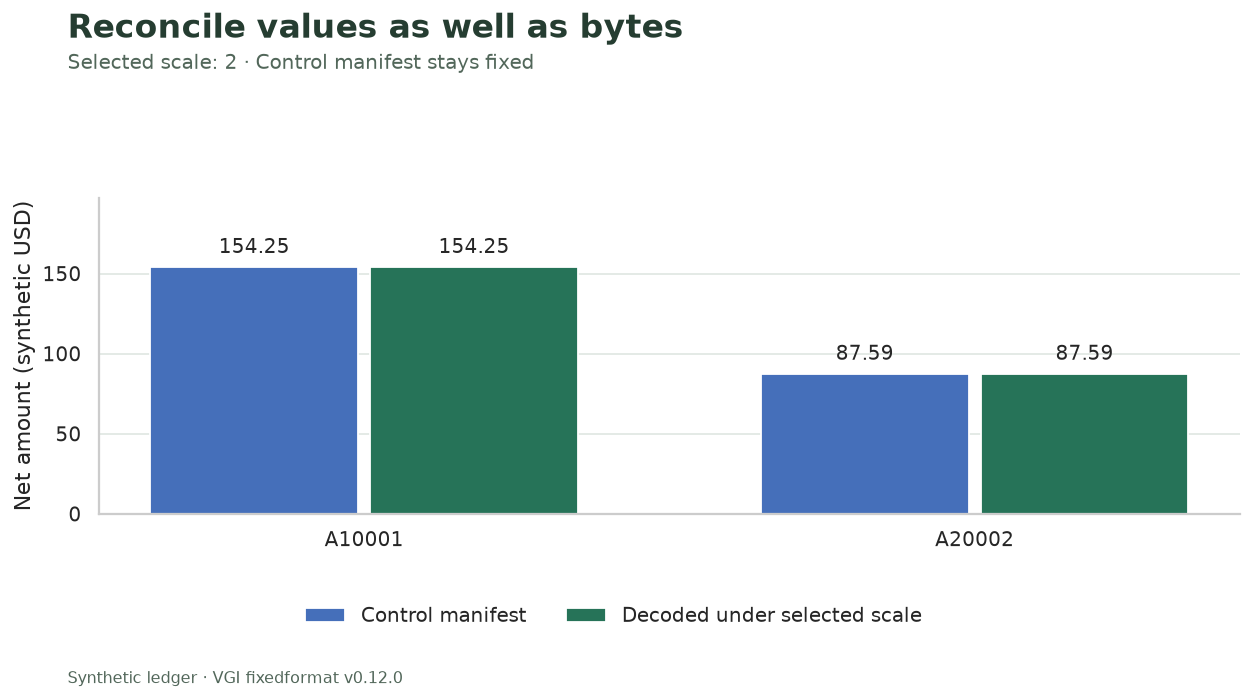

**2 of 2 accounts reconcile** with the manifest. Decoded net amount is **241.84 synthetic USD**; the control total remains **241.84**. A byte-preserving round trip establishes consistency between decoder and encoder, while this separate control tests the selected interpretation. Even matching aggregates cannot prove every individual record is correct: offsetting errors can cancel.

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.4))
x = np.arange(len(reconciliation))
for offset, column, color, label in [
    (-0.18, "expected_usd", "#456fba", "Control manifest"),
    (0.18, "decoded_usd", "#267358", "Decoded under selected scale"),
]:
    values = reconciliation[column].astype(float)
    bars = ax.bar(x + offset, values, 0.34, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:,.{AMOUNT_SCALE}f}" for v in values], padding=5, fontsize=11)
ax.set_xticks(x, reconciliation.account)
ax.set_ylabel("Net amount (synthetic USD)")
ax.set_ylim(
    min(0, reconciliation[["expected_usd", "decoded_usd"]].min().min()) * 1.2,
    reconciliation[["expected_usd", "decoded_usd"]].max().max() * 1.28,
)
ax.grid(axis="x", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Reconcile values as well as bytes",
    f"Selected scale: {AMOUNT_SCALE} · Control manifest stays fixed",
    "02_account_reconciliation.png",
    bottom=0.18,
)
matched = int(reconciliation.status.eq("reconciled").sum())
prose(
    f"**{matched} of {len(reconciliation)} accounts reconcile** with the manifest. "
    f"Decoded net amount is **{reconciliation.decoded_usd.sum():,.{AMOUNT_SCALE}f} synthetic USD**; "
    f"the control total remains **{reconciliation.expected_usd.sum():,.2f}**. "
    "A byte-preserving round trip establishes consistency between decoder and encoder, "
    "while this separate control tests the selected interpretation. Even matching aggregates "
    "cannot prove every individual record is correct: offsetting errors can cancel."
)

## Read the same layout from a fixed-record file

For a file feed, `read_fixed` uses the same spec and returns typed columns directly.
Setup writes the raw records verbatim into a disposable local file, without newlines.
The visible SQL therefore chooses `framing => 'fixed'` with `record_length => 24`.
Encoding, compression and framing are separate from the field layout; changing one
requires the matching source format. This example uses uncompressed ASCII only.

In [13]:
ledger_path.write_bytes(
    b"".join(row.raw_record.encode("ascii") for row in decoded_rows.itertuples())
)

144

In [14]:
%%sql
CREATE TABLE file_rows AS
 SELECT * FROM fixed.main.read_fixed('{{ ledger_path_sql }}', ledger_layout(),
                                    framing => 'fixed', record_length => 24,
                                    encoding => 'ascii', compression => 'none');
SELECT * FROM file_rows ORDER BY reference;

,account,direction,reference,amount
0,A10001,D,REF00001,134.25
1,A10001,D,REF00002,50.00
2,A10001,C,REF00003,30.00
3,A20002,C,REF00004,12.40
4,A20002,D,REF00005,0.00
5,A20002,D,REF00006,99.99


## Verify transport and interpretation separately

The checks below must hold for either permitted scale: field coverage, exact byte
preservation, scalar/file agreement, direction validity and the implied-point formula.
They do **not** assert that the manifest reconciles; the experiment deliberately
changes that result. The status table above is the semantic acceptance check.

In [15]:
%%sql checks <<
SELECT 'Layout covers exactly 24 contiguous bytes' AS invariant,
 (SELECT sum(width)=24 AND min(byte_offset)=0 AND max(byte_offset+width)=24
         AND count(*) FILTER (WHERE depth=0)=count(*) FROM layout_description)
 AND NOT EXISTS (SELECT 1 FROM
   (SELECT byte_offset, lag(byte_offset+width) OVER (ORDER BY byte_offset) AS prior_end
    FROM layout_description) p WHERE prior_end IS NOT NULL AND byte_offset!=prior_end) AS passed
UNION ALL SELECT 'Raw records have the required ASCII byte length',
 NOT EXISTS (SELECT 1 FROM raw_records WHERE octet_length(encode(raw_record))!=24)
UNION ALL SELECT 'Record IDs and references are unique',
 (SELECT count(*)=count(DISTINCT record_id) AND count(*)=count(DISTINCT reference) FROM decoded)
UNION ALL SELECT 'Every direction has a defined sign convention',
 NOT EXISTS (SELECT 1 FROM decoded WHERE direction IS NULL OR direction NOT IN ('D','C'))
UNION ALL SELECT 'Every re-encoded record preserves its input bytes',
 (SELECT count(*) FROM raw_records)=(SELECT count(*) FROM reencoded)
 AND NOT EXISTS (SELECT 1 FROM raw_records r JOIN reencoded p USING(record_id)
                 WHERE encode(r.raw_record) IS DISTINCT FROM p.packed)
UNION ALL SELECT 'Implied-point formula matches the stored digits',
 NOT EXISTS (SELECT 1 FROM decoded
             WHERE amount * CAST(pow(10, {{ AMOUNT_SCALE }}) AS DECIMAL(4,0)) != CAST(right(raw_record,9) AS BIGINT))
UNION ALL SELECT 'Fixed-file and scalar decoding agree including multiplicity',
 NOT EXISTS ((SELECT account,direction,reference,amount FROM decoded
              EXCEPT ALL SELECT account,direction,reference,amount FROM file_rows)
             UNION ALL
             (SELECT account,direction,reference,amount FROM file_rows
              EXCEPT ALL SELECT account,direction,reference,amount FROM decoded))
UNION ALL SELECT 'Every account has exactly one control total',
 (SELECT count(*)=count(DISTINCT account) FROM control_totals)
 AND NOT EXISTS (SELECT 1 FROM account_reconciliation WHERE records IS NULL OR expected_usd IS NULL)
UNION ALL SELECT 'Mismatch classification follows exact decimal equality',
 NOT EXISTS (SELECT 1 FROM account_reconciliation
             WHERE (status='reconciled') IS DISTINCT FROM (decoded_usd=expected_usd));

In [16]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} structural and consistency checks passed.** "
    f"The independent control result remains **{matched}/{len(reconciliation)} reconciled accounts**. "
    "Successful parsing and byte preservation do not replace that semantic acceptance decision."
)

,invariant,passed
0,Layout covers exactly 24 contiguous bytes,True
1,Raw records have the required ASCII byte length,True
2,Record IDs and references are unique,True
3,Every direction has a defined sign convention,True
4,Every re-encoded record preserves its input bytes,True
5,Implied-point formula matches the stored digits,True
6,Fixed-file and scalar decoding agree including...,True
7,Every account has exactly one control total,True
8,Mismatch classification follows exact decimal ...,True


**9 structural and consistency checks passed.** The independent control result remains **2/2 reconciled accounts**. Successful parsing and byte preservation do not replace that semantic acceptance decision.

## Experiment: move the implied decimal point

Change only `AMOUNT_SCALE` from `2` to `3`, restart and run all. Predict which will
change: field boundaries, re-encoded bytes, decoded amounts and reconciliation status.
Compare the amount type, both charts, the byte-equality table and the manifest status.

The same nine stored digits should now represent one tenth of the former amount.
A zero amount stays zero, so a zero-only sample would not expose this scale error.
Both interpretations can round-trip perfectly. Correct scale must come from the feed's
schema and independent controls, rather than from apparent byte-level success.
Reset `AMOUNT_SCALE = 2` to restore the documented fixture interpretation.

In [17]:
con.close()
fixture_directory.cleanup()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)